# 11 · How much can chance alone do? 100 years of control runs

**Question for this notebook.** Notebook 10 showed that three runs of one model can disagree on
the NAO link to rain extremes. But how wide is the range that chance alone produces? The EERIE
archive has a **control run** of each coupled model: 100 years (1950–2049) with the external
forcing held at 1950 conditions, so every difference between one stretch of years and another is
internal variability. Cutting it into windows of 29 winters, the length used for extremes in
version 1, gives the **chance range** of each diagnostic for that model. A historical run or an
observed value outside that range is unlikely to be chance.

**Data.**
- ICON-ESM-ER and IFS-FESOM2-SR control runs (`eerie-control-1950`): monthly sea-level pressure,
  1950–2049 (99 complete winters), and daily precipitation over north-west Europe.
- For comparison: ERA5 and E-OBS (notebook 06) and the three historical runs (notebook 10).

**Method.**
1. NAO index of each control winter along the ERA5 pattern, in ERA5 standard deviations
   (anomalies relative to the control run's own 100-year winter mean).
2. Winter RX1day and R95p from the control run's daily rain (the very-wet-day threshold from all
   100 control winters), land average of each region, same land cells as before.
3. Every window of 29 consecutive winters (71 windows, starting 1951 to 2021): NAO strength and the
   detrended correlation between the NAO and each regional rain index.
4. The 5th to 95th percentile of those 71 values is the chance range.

**A caution.** Consecutive windows overlap, so the 71 values are not independent: 99 winters hold
only about three independent 29-winter samples. The range is therefore an estimate, likely a
little too narrow in the tails. It is still far better than the spread of three runs.

**Sections**
1. Setup
2. Findings
3. The control runs at a glance
4. NAO strength: chance range
5. NAO link to rain extremes: chance range
6. Where the historical runs and observations fall
7. Saved outputs
8. Limitations
9. Open questions

## Background: the terms used in this notebook

| Term | What it means here |
|---|---|
| **Control run** | A simulation with constant 1950 greenhouse gases, aerosols and other forcing. It has weather and year-to-year variability but no climate change, so it shows the model's internal variability alone. |
| **Window** | 29 consecutive winters of the control run, the same length as the 1986–2014 period of version 1. |
| **Chance range** | The 5th to 95th percentile of a diagnostic over all windows: values that the model produces by chance in 90% of 29-winter periods. |
| **Inside / outside the chance range** | A historical run inside the range is consistent with chance; an observed value outside it means the model rarely produces what was observed. |
| **Drift** | A slow trend in a control run as the model adjusts. Series are detrended within each window, as in version 1. |

## 1. Setup

**What this cell does.** Loads the project code and the ERA5 NAO pattern used throughout the
project, and builds the common land mask.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
from pathlib import Path
from eerie_uk import climatology as clim, extremes as ex, nao, plotting, regions, relationships as rel, store

pd.set_option('display.width', 220, 'display.float_format', '{:.2f}'.format)
CONTROLS = {'icon-esm-er': 'icon-esm-er.control', 'ifs-fesom2-sr': 'ifs-fesom2-sr.control'}
WINDOW = 29
LABEL = plotting.label_of

era5_nao = nao.leading_eof(nao.winter_anomalies(store.load('era5', 'mon', 'psl', 'north_atlantic')))
grid = ex.indices_for('icon-esm-er')
eobs = regions.to_grid(ex.indices_for('e-obs'), grid)
land = regions.land_mask(grid.lat, grid.lon)
common = land & eobs.rx1day_djf.isel(year_djf=0).notnull()

## 2. Findings

Control runs with constant 1950 forcing, 99 winters each (1951–2049); 71 overlapping windows of 29 winters. Chance range: 5th to 95th percentile over the windows. Historical runs and references: 1986–2014 (notebooks 06 and 10).

| | ICON-ESM-ER | IFS-FESOM2-SR | Observed |
|---|---|---|---|
| NAO strength, chance range (ERA5 SD units) | 0.68 to 0.77 (highest window 0.80) | 0.58 to 0.94 (highest 0.95) | ERA5 1.04 (1986–2014) |
| NAO link to R95p, UK and Ireland | 0.26 to 0.40 | 0.25 to 0.67 | 0.35 (ERA5), 0.51 (E-OBS) |
| NAO link to R95p, western Norway | 0.50 to 0.73 (highest 0.77) | 0.48 to 0.76 (highest 0.78) | 0.81 (both) |
| NAO link to R95p, north-west France | −0.40 to +0.08 (highest 0.11) | −0.04 to +0.27 | 0.28 (ERA5), 0.34 (E-OBS) |
| Drift over 100 years | NAO +0.02 SD per decade; UK R95p +0.02% per decade | NAO −0.04 SD per decade; UK R95p −0.2% per decade | – |

**What this means, in plain words**

1. **No 29-winter period of either model reaches the observed NAO strength.** ERA5's NAO over 1986–2014 has a strength of 1.04 in these units; the strongest window of ICON-ESM-ER's control run reaches 0.80, of IFS-FESOM2-SR's 0.95. Together with notebook 10 (all six historical runs weaker than ERA5), a too-weak NAO is a robust property of both models, more pronounced in ICON-ESM-ER.
2. **Over western Norway the observed NAO link is stronger than anything either model produces.** The observed correlation (0.81) lies above every one of the 71 control windows of both models and above all six historical runs. This is the most robust model–observation difference in the NAO-to-extremes link found in this project.
3. **Over north-west France ICON-ESM-ER's link has the wrong sign as a model property.** Its control run almost never produces a positive link (highest window 0.11, median −0.14), while both references show about +0.3. The third historical run's +0.18 is the exception, not the rule. IFS-FESOM2-SR's chance range reaches up to the observed values, so it is consistent with them.
4. **Over UK and Ireland the observations are within chance for IFS-FESOM2-SR, and at the edge for ICON-ESM-ER.** ERA5's 0.35 lies inside both chance ranges; E-OBS's 0.51 lies inside IFS-FESOM2-SR's range but above ICON-ESM-ER's (0.26 to 0.40). With the two references disagreeing, no firm verdict is possible.
5. **The control runs underestimate chance.** Several historical runs fall outside their model's control range (for example ICON-ESM-ER r2 at 0.06 for UK and Ireland, below its control range of 0.26 to 0.40). Overlapping windows from one 99-winter run sample only about three independent periods, and the historical runs also differ in forcing. The ranges are therefore lower bounds on chance; differences that lie well outside them, as over western Norway, are the ones that can be trusted.
6. **Drift is negligible** (NAO trends within ±0.04 SD per decade, UK R95p within ±0.2% per decade), so the windows can be compared directly.

**Answer to the question.** Chance alone moves the NAO link to UK and Ireland rain extremes by about ±0.1 to ±0.2 within one model, enough to cover the difference between the two models and between the two references. It does not explain three results: both models' NAO is too weak, both models' NAO link over western Norway is too weak, and ICON-ESM-ER's link over north-west France has the wrong sign. These are model properties.

## 3. The control runs at a glance

**What this cell does.** Computes the winter NAO index of each control run and its winter RX1day and
R95p from daily rain, and shows the NAO index through the 100 years.

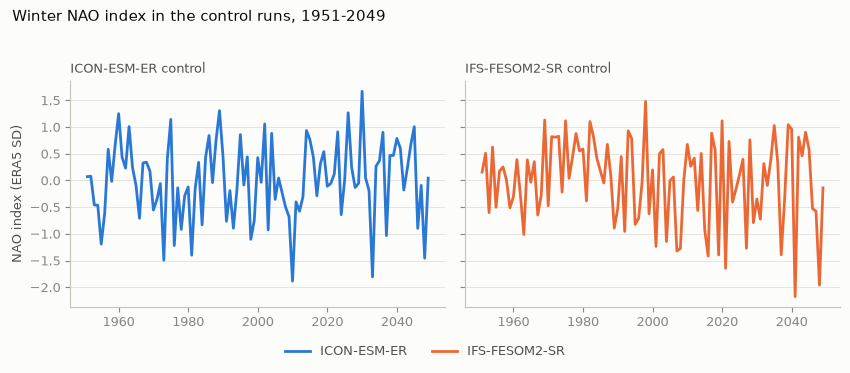

In [2]:
control_nao, control_rain = {}, {}
for model, run in CONTROLS.items():
    winters = nao.winter_anomalies(store.load(run, 'mon', 'psl', 'north_atlantic'), (1950, 2049))
    control_nao[model] = nao.project(winters, era5_nao.vector) / era5_nao.amplitude
    daily = store.load(run, 'day', 'pr', 'nw_europe')
    threshold = ex.wet_day_threshold(daily, base=(1950, 2049), period='DJF')
    control_rain[model] = {'R95p': ex.r95p(daily, threshold, 'DJF'), 'RX1day': ex.rx1day(daily, 'DJF')}
panels = {LABEL(m).split()[0] + ' control': {m: (control_nao[m].year.values, control_nao[m].values)} for m in CONTROLS}
plotting.plot_line_panels(panels, ylabel='NAO index (ERA5 SD)', title='Winter NAO index in the control runs, 1951-2049', columns=2, sharey=True);

**Figure 1.** The winter NAO index of each control run along the ERA5 pattern. There is no
climate change in these runs, so any slow change is drift or long-term internal variability.

**What this cell does.** Checks the size of drift: the linear trend of the NAO index and of UK and
Ireland winter R95p over the 100 control years.

In [3]:
rows = []
for m in CONTROLS:
    uk = clim.regional_mean(control_rain[m]['R95p'].where(common), 'uk_ireland')
    rows.append({'model': LABEL(m).split()[0], 'NAO trend (SD per decade)': nao.trend(control_nao[m].year, control_nao[m])['trend per decade'],
                 'UK R95p trend (% of mean per decade)': 100 * nao.trend(uk.year, uk)['trend per decade'] / float(uk.mean())})
pd.DataFrame(rows).set_index('model')

,NAO trend (SD per decade),UK R95p trend (% of mean per decade)
model,,
ICON-ESM-ER,0.02,0.02
IFS-FESOM2-SR,-0.04,-0.20


## 4. NAO strength: chance range

**What this cell does.** For every 29-winter window of each control run, the NAO strength
(standard deviation of the index along the ERA5 pattern, in ERA5 units). Then the chance range,
and for comparison the strength of the three historical runs over 1986–2014 in the same units.

In [4]:
def windows(series):
    years = series.year.values
    return [np.arange(start, start + WINDOW) for start in range(years[0], years[-1] - WINDOW + 2)]

historical = {m: [m, f'{m}.r2', f'{m}.r3'] for m in CONTROLS}

def historical_nao(run):
    psl = store.load(run, 'mon', 'psl', 'north_atlantic')
    w = nao.winter_anomalies(clim.period(psl, 1975, 2014), (1975, 2014))
    return (nao.project(w, era5_nao.vector) / era5_nao.amplitude).sel(year=slice(1986, 2014))

era5_window = (nao.project(nao.winter_anomalies(store.load('era5', 'mon', 'psl', 'north_atlantic')), era5_nao.vector)
               / era5_nao.amplitude).sel(year=slice(1986, 2014))
rows = []
for m in CONTROLS:
    values = [float(control_nao[m].sel(year=y).std(ddof=1)) for y in windows(control_nao[m])]
    runs = [float(historical_nao(r).std(ddof=1)) for r in historical[m]]
    rows.append({'model': LABEL(m).split()[0], 'windows': len(values), 'chance range 5%': np.percentile(values, 5),
                 'median': np.median(values), 'chance range 95%': np.percentile(values, 95), 'highest window': max(values),
                 'historical runs 1986-2014': ', '.join(f'{v:.2f}' for v in runs)})
strength = pd.DataFrame(rows).set_index('model')
print(f'ERA5 1986-2014: {float(era5_window.std(ddof=1)):.2f}')
strength

ERA5 1986-2014: 1.04


,windows,chance range 5%,median,chance range 95%,highest window,historical runs 1986-2014
model,,,,,,
ICON-ESM-ER,71,0.68,0.72,0.77,0.80,"0.52, 0.59, 0.69"
IFS-FESOM2-SR,71,0.58,0.79,0.94,0.95,"0.78, 0.87, 0.95"


**How to read this table.** All values are standard deviations of the winter NAO index in ERA5
units; ERA5 itself has 1.00 over 1951–2014 and the value printed above over 1986–2014. If ERA5's
value lies above the highest control window, no 29-winter period of the model reaches the observed
NAO strength.

## 5. NAO link to rain extremes: chance range

**What this cell does.** For every window, region and rain index: the detrended correlation between
the control run's winter NAO and the land-average winter index. Summarised as the chance range.

In [5]:
rows = []
for m in CONTROLS:
    for region in regions.SUBREGIONS:
        for key, field in control_rain[m].items():
            series = clim.regional_mean(field.where(common), region)
            for years in windows(control_nao[m]):
                fit = rel.regress_series(series.sel(year=years).values, control_nao[m].sel(year=years).values)
                rows.append({'model': m, 'region': regions.LABELS[region], 'index': key, 'start': int(years[0]), 'r': fit['r']})
window_link = pd.DataFrame(rows)
chance = (window_link.groupby(['region', 'index', 'model']).r
          .describe(percentiles=[0.05, 0.5, 0.95])[['5%', '50%', '95%', 'min', 'max']].unstack('model'))
chance

5%                       50%                       95%                       min                       max              
model                    icon-esm-er ifs-fesom2-sr icon-esm-er ifs-fesom2-sr icon-esm-er ifs-fesom2-sr icon-esm-er ifs-fesom2-sr icon-esm-er ifs-fesom2-sr
region            index                                                                                                                                   
North-west France R95p         -0.40         -0.04       -0.14          0.12        0.08          0.27       -0.46         -0.12        0.11          0.31
                  RX1day       -0.31          0.09        0.14          0.24        0.31          0.35       -0.39         -0.00        0.34          0.42
UK and Ireland    R95p          0.26          0.25        0.34          0.43        0.40          0.67        0.22          0.07        0.46          0.69
                  RX1day        0.14          0.11        0.30          0.35        0.39          0.51        0.08         -0.11        0.41          0.56
Western Norway    R95p          0.50          0.48        0.63          0.66        0.73          0.76        0.48          0.42        0.77          0.78
                  RX1day        0.33          0.39        0.48          0.58        0.60          0.72        0.22          0.34        0.63          0.75

## 6. Where the historical runs and observations fall

**What this cell does.** Puts the chance range of each model next to the correlations of its three
historical runs and of the two references (from notebook 10), for each region and rain index.

In [6]:
members = pd.read_parquet('../app_assets/members_nao_link.parquet')
rows = []
for region in regions.SUBREGIONS:
    for key in ('R95p', 'RX1day'):
        part = members[(members.region == regions.LABELS[region]) & (members['index'] == key)].set_index('source')
        for m in CONTROLS:
            values = window_link[(window_link.model == m) & (window_link.region == regions.LABELS[region]) & (window_link['index'] == key)].r
            low, high = np.percentile(values, [5, 95])
            runs = [part.r[s] for s in historical[m]]
            rows.append({'region': regions.LABELS[region], 'index': key, 'model': LABEL(m).split()[0],
                         'chance range': f'{low:.2f} to {high:.2f}', 'historical runs': ', '.join(f'{v:.2f}' for v in runs),
                         'runs inside': sum(low <= v <= high for v in runs),
                         'E-OBS': part.r['e-obs'], 'ERA5': part.r['era5'],
                         'E-OBS inside': bool(low <= part.r['e-obs'] <= high), 'ERA5 inside': bool(low <= part.r['era5'] <= high)})
placement = pd.DataFrame(rows)
placement

,region,index,model,chance range,historical runs,runs inside,E-OBS,ERA5,E-OBS inside,ERA5 inside
0,UK and Ireland,R95p,ICON-ESM-ER,0.26 to 0.40,"0.36, 0.06, 0.49",1,0.51,0.35,False,True
1,UK and Ireland,R95p,IFS-FESOM2-SR,0.25 to 0.67,"0.60, 0.48, 0.21",2,0.51,0.35,True,True
2,UK and Ireland,RX1day,ICON-ESM-ER,0.14 to 0.39,"0.28, -0.14, 0.22",2,0.56,0.32,False,True
3,UK and Ireland,RX1day,IFS-FESOM2-SR,0.11 to 0.51,"0.57, 0.52, 0.06",0,0.56,0.32,False,True
4,Western Norway,R95p,ICON-ESM-ER,0.50 to 0.73,"0.52, 0.71, 0.69",3,0.81,0.81,False,False
5,Western Norway,R95p,IFS-FESOM2-SR,0.48 to 0.76,"0.66, 0.69, 0.60",3,0.81,0.81,False,False
6,Western Norway,RX1day,ICON-ESM-ER,0.33 to 0.60,"0.46, 0.60, 0.60",3,0.78,0.74,False,False
7,Western Norway,RX1day,IFS-FESOM2-SR,0.39 to 0.72,"0.46, 0.60, 0.44",3,0.78,0.74,False,False
8,North-west France,R95p,ICON-ESM-ER,-0.40 to 0.08,"-0.46, -0.32, 0.18",1,0.34,0.28,False,False
9,North-west France,R95p,IFS-FESOM2-SR,-0.04 to 0.27,"0.25, -0.01, -0.02",3,0.34,0.28,False,False


**What this cell does.** Draws the same comparison for winter R95p: for each region and model, a
box from the 5th to the 95th percentile of the control windows, the three historical runs as dots,
and the two references as vertical lines.

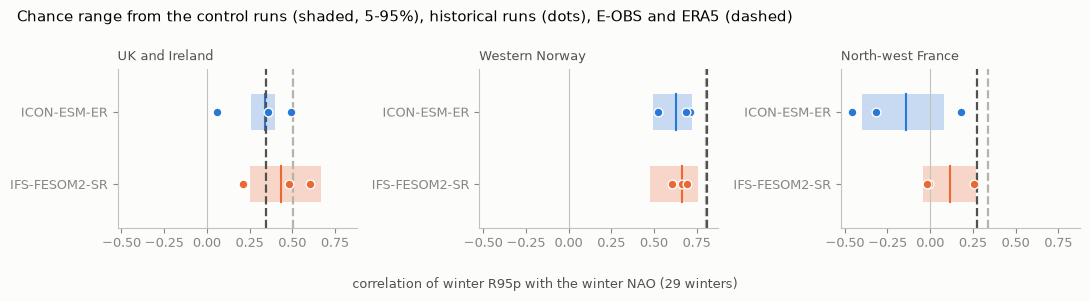

In [7]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(11, 2.9), facecolor=plotting.SURFACE, sharex=True)
for ax, region in zip(axes, regions.SUBREGIONS):
    part = members[(members.region == regions.LABELS[region]) & (members['index'] == 'R95p')].set_index('source')
    for row, m in enumerate(CONTROLS):
        values = window_link[(window_link.model == m) & (window_link.region == regions.LABELS[region]) & (window_link['index'] == 'R95p')].r
        low, mid, high = np.percentile(values, [5, 50, 95])
        ax.add_patch(plt.Rectangle((low, row - 0.25), high - low, 0.5, color=plotting.colour_of(m), alpha=0.25, linewidth=0))
        ax.plot([mid, mid], [row - 0.25, row + 0.25], color=plotting.colour_of(m), linewidth=1.5)
        ax.scatter([part.r[s] for s in historical[m]], [row] * 3, color=plotting.colour_of(m), edgecolors=plotting.SURFACE, s=40, zorder=3)
    for ref in ('e-obs', 'era5'):
        ax.axvline(part.r[ref], color=plotting.colour_of(ref), linewidth=1.6, linestyle='--')
    ax.axvline(0, color=plotting.AXIS, linewidth=0.8)
    ax.set_yticks([0, 1], [LABEL(m).split()[0] for m in CONTROLS])
    ax.set_ylim(1.6, -0.6)
    ax.set_title(regions.LABELS[region], loc='left', fontsize=9, color=plotting.INK_SECONDARY)
    plotting._style(ax)
fig.supxlabel('correlation of winter R95p with the winter NAO (29 winters)', fontsize=9, color=plotting.INK_SECONDARY)
fig.suptitle('Chance range from the control runs (shaded, 5-95%), historical runs (dots), E-OBS and ERA5 (dashed)',
             x=0.02, ha='left', fontsize=11)
fig.tight_layout();

**Figure 2.** Shaded box: the range of the NAO–R95p correlation over 90% of 29-winter windows of
the control run (line: median). Dots: the three historical runs (1986–2014). Dashed lines: E-OBS
(light grey) and ERA5 (dark grey). A reference line far outside a model's box means the model
rarely produces the observed link.

## 7. Saved outputs

**What this cell does.** Saves the window-by-window correlations and the placement table to
`app_assets/`, with provenance.

In [8]:
from eerie_uk import provenance
out = Path('../app_assets')
meta = dict(inputs={'control runs': 'data/<model>.control/', 'members': 'app_assets/members_nao_link.parquet'},
            window_winters=WINDOW, control_years='1950-2049')
provenance.write_table(window_link, out / 'control_window_link.parquet', 'NAO-rain-extremes correlation in every 29-winter window of the control runs', **meta)
provenance.write_table(placement, out / 'control_placement.parquet', 'Chance range from control runs and where historical runs and references fall', **meta)
provenance.write_table(strength.reset_index(), out / 'control_nao_strength.parquet', 'NAO strength chance range from control-run windows', **meta)
print('saved 3 tables')

saved 3 tables


## 8. Limitations

- **Overlapping windows.** 99 winters contain only about three independent 29-winter samples, so the
  chance range is an estimate and probably slightly too narrow at the tails.
- **1950 forcing.** The control runs have no climate change; the historical runs do. Where forcing
  itself changes the NAO link, the comparison mixes the two. Within 1986–2014 this effect is
  expected to be small compared with internal variability.
- **Model chance, not observational chance.** The range shows what *this model* does by chance; it
  is used to ask whether the observed value is unusual *for the model*.
- **Daily rain only.** The control runs were downloaded with daily precipitation only, so TXx is not
  tested here.

## 9. Open questions

1. Is the observed link over western Norway (0.81) outside the chance range of both models because
   of their weak NAO, or because of how rain responds to a given NAO swing?
2. Would a longer control run, or several, widen the ranges enough to include the observations?